In [1]:
# Setup and library imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Plot configuration
plt.style.use('seaborn-v0_8-darkgrid' if 'seaborn-v0_8-darkgrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['font.size'] = 11

np.random.seed(42)

## The Lag Operator ($B$) and the Difference Operator ($\nabla$)

To manipulate time series algebraically we use two fundamental mathematical operators:

**Backshift / Lag Operator ($B$ or $L$):**
   Shifts the time index back by one position:
   $$ B X_t = X_{t-1}, \quad B^k X_t = X_{t-k} $$

**First Difference Operator ($\nabla$ or $\Delta$):**
   Represents the incremental change of the series between two consecutive instants:
   $$ \nabla X_t = (1 - B) X_t = X_t - X_{t-1} $$

**Higher-Order Differences ($\nabla^d$):**
   Applying the operator $d$ consecutive times:
   $$ \nabla^2 X_t = \nabla(\nabla X_t) = (1 - B)^2 X_t = (1 - 2B + B^2) X_t = X_t - 2X_{t-1} + X_{t-2} $$

### **Integrated Processes of Order $d$, $I(d)$**
A series $X_t$ is said to be **integrated of order $d$** (denoted $X_t \sim I(d)$) if it is not stationary in levels, but becomes stationary after being differenced $d$ times:
$$ Y_t = \nabla^d X_t \sim I(0) \quad (\text{where } I(0) \text{ denotes a stationary process}) $$

*Example:* A Random Walk $X_t = X_{t-1} + \epsilon_t$ is an $I(1)$ process, because:
$$ \nabla X_t = X_t - X_{t-1} = \epsilon_t \sim WN(0, \sigma^2) \quad (\text{stationary}) $$

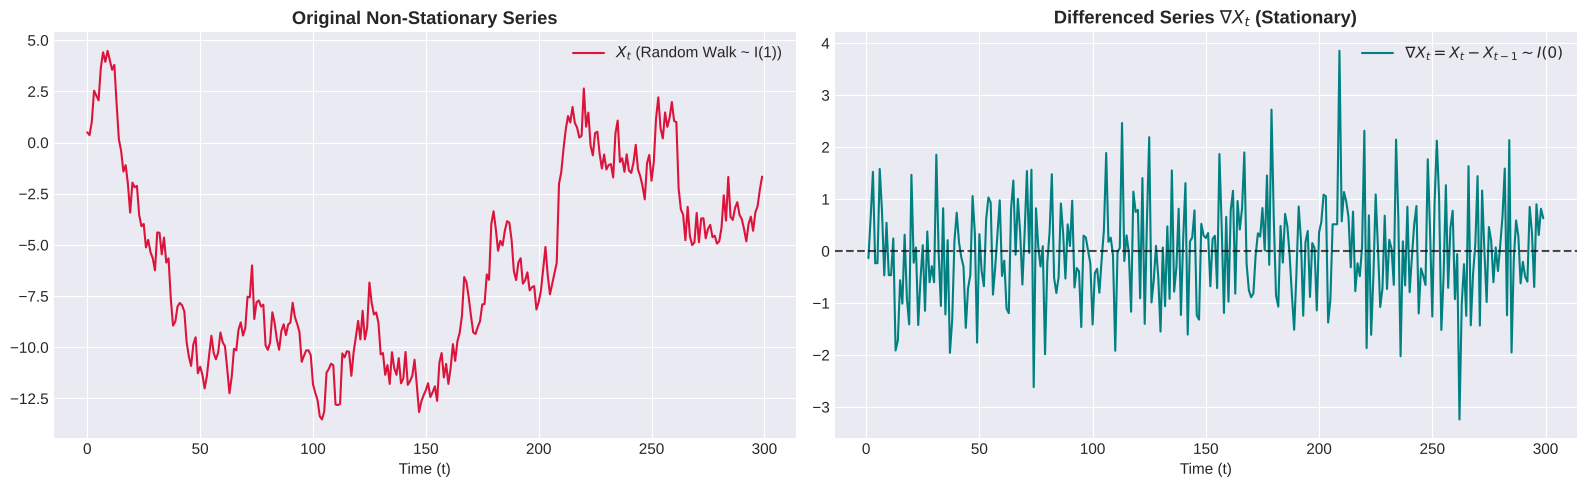

In [2]:
# Simulation: making a Random Walk stationary through differencing
n = 300
white_noise = np.random.normal(0, 1, n)
random_walk = np.cumsum(white_noise) # I(1) process

# Apply the first difference operator (pandas .diff())
diff_random_walk = pd.Series(random_walk).diff().dropna() # Becomes I(0)

# Comparison plot
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(random_walk, color='crimson', label=r'$X_t$ (Random Walk ~ I(1))')
axes[0].set_title("Original Non-Stationary Series", fontweight='bold')
axes[0].set_xlabel("Time (t)")
axes[0].legend()

axes[1].plot(diff_random_walk, color='teal', label=r'$\nabla X_t = X_t - X_{t-1} \sim I(0)$')
axes[1].axhline(0, color='black', linestyle='--', alpha=0.7)
axes[1].set_title(r"Differenced Series $\nabla X_t$ (Stationary)", fontweight='bold')
axes[1].set_xlabel("Time (t)")
axes[1].legend()

plt.tight_layout()
plt.show()

## Unit Root Tests

How can we formally and rigorously establish whether a series needs differencing? We use the **Dickey-Fuller (DF) Test** and its extended version, the **Augmented Dickey-Fuller (ADF) Test**.

### **The Test Equation**
Consider an autoregressive model $AR(1)$:
$$ X_t = \phi X_{t-1} + \epsilon_t $$

If $\phi = 1$, the process has a **unit root** (it is a non-stationary Random Walk).  
Subtracting $X_{t-1}$ from both sides gives the regression form:
$$ \Delta X_t = (\phi - 1) X_{t-1} + \epsilon_t = \delta X_{t-1} + \epsilon_t $$
where $\delta = \phi - 1$.

The hypotheses of the test are:
$$ \begin{cases} H_0: \delta = 0 \quad (\phi = 1 \implies \text{Unit Root Present / Non-Stationary}) \\ H_1: \delta < 0 \quad (\phi < 1 \implies \text{Stationary Process}) \end{cases} $$

### **Why don't we use Student's t-test?**
Under the null hypothesis $H_0$, $X_t$ is a Random Walk, so its variance grows over time and the test statistic **does not follow a standard Student's t distribution**, but the **Dickey-Fuller distribution**.

### **Augmented Dickey-Fuller (ADF) Test**
If the residuals $\epsilon_t$ are autocorrelated, the basic DF test loses validity. The **ADF** fixes this problem by adding lags of the differences $\Delta X_{t-i}$:

$$ \Delta X_t = \alpha + \beta t + \delta X_{t-1} + \sum_{i=1}^p \gamma_i \Delta X_{t-i} + \epsilon_t $$
*   $\alpha$: Drift term (intercept).
*   $\beta t$: Deterministic time trend.
*   $\sum \gamma_i \Delta X_{t-i}$: Lag terms to absorb serial autocorrelation in the residuals.

In [3]:
# Reusable helper function for the ADF Test and diagnostics
def check_stationarity(series, title=""):
    """
    Runs the Augmented Dickey-Fuller (ADF) test and prints the detailed results.
    """
    series_clean = pd.Series(series).dropna()
    result = adfuller(series_clean, autolag='AIC')
    
    adf_stat = result[0]
    p_value = result[1]
    used_lags = result[2]
    n_obs = result[3]
    critical_values = result[4]
    
    print(f"==================================================")
    print(f"   TEST AUGMENTED DICKEY-FULLER (ADF): {title}")
    print(f"==================================================")
    print(f"ADF Statistic:     {adf_stat:.4f}")
    print(f"p-value:           {p_value:.4e}")
    print(f"Lags used:         {used_lags}")
    print(f"Number of observations: {n_obs}")
    print("Critical Values:")
    for key, val in critical_values.items():
        print(f"   {key}: {val:.4f}")
    print("--------------------------------------------------")
    
    if p_value <= 0.05:
        print("RESULT: REJECT H0 (p-value <= 0.05) -> The series is STATIONARY (I(0))")
    else:
        print("RESULT: FAIL TO REJECT H0 (p-value > 0.05) -> The series is NON-STATIONARY (Unit Root present)")
    print(f"==================================================\n")

# Test 1: On the original Random Walk
check_stationarity(random_walk, title="Random Walk (Levels)")

# Test 2: On the differenced series
check_stationarity(diff_random_walk, title="Differenced Random Walk (Gradient)")

   TEST AUGMENTED DICKEY-FULLER (ADF): Random Walk (Levels)
ADF Statistic:     -1.9084
p-value:           3.2812e-01
Lags used:         1
Number of observations: 298
Critical Values:
   1%: -3.4525
   5%: -2.8713
   10%: -2.5720
--------------------------------------------------
RESULT: FAIL TO REJECT H0 (p-value > 0.05) -> The series is NON-STATIONARY (Unit Root present)

   TEST AUGMENTED DICKEY-FULLER (ADF): Differenced Random Walk (Gradient)
ADF Statistic:     -18.5895
p-value:           2.0741e-30
Lags used:         0
Number of observations: 298
Critical Values:
   1%: -3.4525
   5%: -2.8713
   10%: -2.5720
--------------------------------------------------
RESULT: REJECT H0 (p-value <= 0.05) -> The series is STATIONARY (I(0))



/tmp/ipykernel_503/3019012255.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series_clean, autolag='AIC')
/tmp/ipykernel_503/3019012255.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series_clean, autolag='AIC')


## Handling Series with Trend and Seasonality

In practical applications (e.g. the `AirPassengers` dataset or economic series), we face series that exhibit **both a non-stationary trend and seasonality**.

To make them stationary we apply a multi-step strategy:
1. **Logarithmic Transformation ($\ln$):** To stabilize the variance growing over time.
2. **Seasonal Differencing ($\nabla_s$):** $\nabla_s X_t = X_t - X_{t-s}$ (where $s=12$ for monthly data).
3. **Ordinary Differencing ($\nabla$):** If a residual trend remains after seasonal differencing.

/tmp/ipykernel_503/3019012255.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series_clean, autolag='AIC')


   TEST AUGMENTED DICKEY-FULLER (ADF): Raw Series
ADF Statistic:     8.8528
p-value:           1.0000e+00
Lags used:         14
Number of observations: 225
Critical Values:
   1%: -3.4598
   5%: -2.8745
   10%: -2.5737
--------------------------------------------------
RESULT: FAIL TO REJECT H0 (p-value > 0.05) -> The series is NON-STATIONARY (Unit Root present)



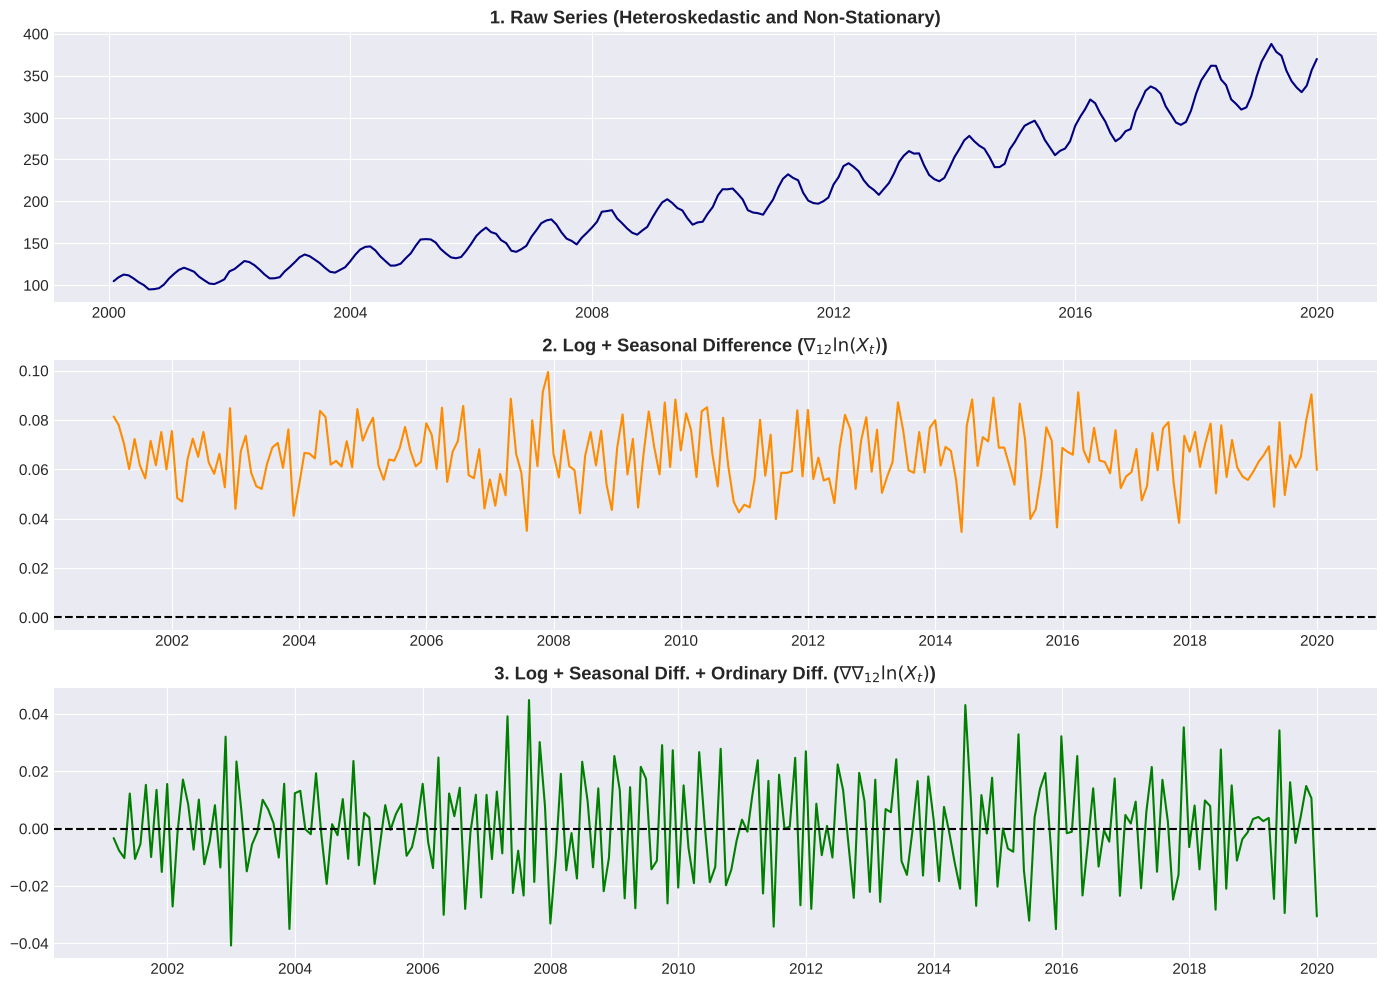

   TEST AUGMENTED DICKEY-FULLER (ADF): Final Transformed Series
ADF Statistic:     -6.8528
p-value:           1.6776e-09
Lags used:         15
Number of observations: 211
Critical Values:
   1%: -3.4617
   5%: -2.8753
   10%: -2.5741
--------------------------------------------------
RESULT: REJECT H0 (p-value <= 0.05) -> The series is STATIONARY (I(0))



/tmp/ipykernel_503/3019012255.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series_clean, autolag='AIC')


In [4]:
# Generate a synthetic series with trend, monthly seasonality (s=12) and growing variance
n_periods = 240  # 20 years of monthly data (20 * 12 = 240)
t = np.arange(1, n_periods + 1)

trend = 0.05 * t
seasonality = 10 * np.sin(2 * np.pi * t / 12)
noise = np.random.normal(0, 1, len(t))

# Series with heteroskedasticity (variance proportional to the level)
raw_series = (100 + trend + seasonality + noise) * np.exp(0.005 * t)

# Build a DataFrame with aligned length (len(raw_series))
df = pd.DataFrame({
    'Date': pd.date_range(start='2000-01-01', periods=len(raw_series), freq='ME'),
    'Value': raw_series
})
df.set_index('Date', inplace=True)

# Visualization and ADF Test on the raw series
check_stationarity(df['Value'], title="Raw Series")

# Step 1: Log transformation to stabilize the variance
df['Log_Value'] = np.log(df['Value'])

# Step 2: Seasonal difference (s=12)
df['Seasonal_Diff'] = df['Log_Value'].diff(12)

# Step 3: Ordinary difference (s=1)
df['Final_Diff'] = df['Seasonal_Diff'].diff(1)

# Plot the transformations
fig, axes = plt.subplots(3, 1, figsize=(14, 10))

axes[0].plot(df['Value'], color='navy')
axes[0].set_title("1. Raw Series (Heteroskedastic and Non-Stationary)", fontweight='bold')

axes[1].plot(df['Seasonal_Diff'], color='darkorange')
axes[1].axhline(0, color='black', linestyle='--')
axes[1].set_title(r"2. Log + Seasonal Difference ($\nabla_{12} \ln(X_t)$)", fontweight='bold')

axes[2].plot(df['Final_Diff'], color='green')
axes[2].axhline(0, color='black', linestyle='--')
axes[2].set_title(r"3. Log + Seasonal Diff. + Ordinary Diff. ($\nabla \nabla_{12} \ln(X_t)$)", fontweight='bold')

plt.tight_layout()
plt.show()

# Final ADF Test
check_stationarity(df['Final_Diff'], title="Final Transformed Series")

## The Turning Point Test for Randomness

After applying the difference operator $\nabla$ and confirming via the **ADF Test** that the series no longer has unit roots ($I(0)$), we want further confirmation: **does the differenced series behave, to all effects, like an i.i.d. White Noise?**


### **Turning Point Test**
In a sequence of observations $(X_1, X_2, \dots, X_n)$, a point $X_i$ (for $1 < i < n$) is defined as a **turning point** if it is a local maximum or a local minimum:
$$ (X_{i-1} < X_i > X_{i+1}) \quad \text{or} \quad (X_{i-1} > X_i < X_{i+1}) $$

If the series is generated by a purely random process $WN(0, \sigma^2)$ (White Noise with independent and identically distributed variables):
* The probability that three consecutive values produce a turning point is exactly $p = \frac{2}{3}$.
* For a sample of size $n$, the expected number $T$ of turning points has theoretical mean and variance:
  $$ \mathbb{E}[T] = \frac{2n - 4}{3}, \quad \text{Var}(T) = \frac{16n - 29}{90} $$

As $n \to \infty$, the normalized test statistic converges to a **Standard Normal** distribution:
$$ Z = \frac{T - \mathbb{E}[T]}{\sqrt{\text{Var}(T)}} \sim \mathcal{N}(0, 1) $$

If $|Z| \le 1.96$, **we cannot reject the null hypothesis** that the transformed series is a White Noise.

In [5]:
def turning_point_test(series, title=""):
    """
    Runs the Turning Point Test to check the randomness (White Noise) of a series.
    """
    x = np.asarray(pd.Series(series).dropna())
    n = len(x)
    
    # Count the turning points (local maxima and minima)
    tp = 0
    for i in range(1, n - 1):
        if (x[i] > x[i-1] and x[i] > x[i+1]) or (x[i] < x[i-1] and x[i] < x[i+1]):
            tp += 1
            
    # Theoretical moments under H0: i.i.d. White Noise
    mean_tp = (2 * n - 4) / 3.0
    var_tp = (16 * n - 29) / 90.0
    std_tp = np.sqrt(var_tp)
    
    # Z statistic
    z_stat = (tp - mean_tp) / std_tp
    p_value = 2 * (1 - stats.norm.cdf(abs(z_stat))) if 'stats' in globals() else None
    
    print(f"==================================================")
    print(f"   TURNING POINT TEST (WHITE NOISE CHECK): {title}")
    print(f"==================================================")
    print(f"Number of observations (n):        {n}")
    print(f"Observed Turning Points (T):       {tp}")
    print(f"Expected Turning Points E[T]:      {mean_tp:.2f}")
    print(f"Theoretical Standard Deviation:    {std_tp:.2f}")
    print(f"Z Statistic:                       {z_stat:.4f}")
    print("--------------------------------------------------")
    
    if abs(z_stat) <= 1.96:
        print("RESULT: FAIL TO REJECT H0 (|Z| <= 1.96)")
        print("-> The differenced series is consistent with a WHITE NOISE (random i.i.d.).")
    else:
        print("RESULT: REJECT H0 (|Z| > 1.96)")
        print("-> The series still shows dependent structure (it is not a pure White Noise).")
    print(f"==================================================\n")

# Make sure scipy.stats is imported for the p-value if needed
import scipy.stats as stats

# Test 1: On the original Random Walk (not differenced -> we expect rejection)
turning_point_test(random_walk, title="Random Walk in Levels (Non-Stationary)")

# Test 2: On the differenced Random Walk (must be White Noise)
turning_point_test(diff_random_walk, title="Differenced Random Walk (nabla X_t)")

   TURNING POINT TEST (WHITE NOISE CHECK): Random Walk in Levels (Non-Stationary)
Number of observations (n):        300
Observed Turning Points (T):       157
Expected Turning Points E[T]:      198.67
Theoretical Standard Deviation:    7.28
Z Statistic:                       -5.7228
--------------------------------------------------
RESULT: REJECT H0 (|Z| > 1.96)
-> The series still shows dependent structure (it is not a pure White Noise).

   TURNING POINT TEST (WHITE NOISE CHECK): Differenced Random Walk (nabla X_t)
Number of observations (n):        299
Observed Turning Points (T):       197
Expected Turning Points E[T]:      198.00
Theoretical Standard Deviation:    7.27
Z Statistic:                       -0.1376
--------------------------------------------------
RESULT: FAIL TO REJECT H0 (|Z| <= 1.96)
-> The differenced series is consistent with a WHITE NOISE (random i.i.d.).

